# Advanced Array Mathematics & Array Transformations
**Komputasi Statistika II Pertemuan 11**

**09/11/26**

In [1]:
# Advanced Array Mathematics & Array Transformations

# Install NumPy (jika belum, hapus # pada baris berikut)
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


---
## 1. Broadcasting in NumPy

### Introduction to Broadcasting

In [3]:
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


### Broadcasting Rules


In [4]:
# Broadcasting Rules
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


### Shape Compatibility


In [5]:
# Shape Compatibility
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


### Broadcasting Across Rows and Columns


In [6]:
# Broadcasting Across Rows and Columns
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)


**Applied example: Centering by Column Mean**


In [7]:
# Applied example: Centering by Column Mean
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


---
## 2. Saving and Loading Arrays

### Working with `.npy` Files

In [8]:
# Working with .npy Files
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


### Loading Arrays (`np.load`)


In [9]:
# Loading Arrays (np.load)
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


### Saving Arrays (`np.save`)


In [10]:
# Saving Arrays (np.save)
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]


### Inspecting Loaded Arrays


In [11]:
# Inspecting Loaded Arrays
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


---
## 3. Image Arrays and Transformations

### Understanding RGB and RGBA Arrays

In [12]:
# Understanding RGB and RGBA Arrays
# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


### Selecting Image Color Channels


In [13]:
# Selecting Image Color Channels
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)


### Manipulating Pixel Values


In [14]:
# Manipulating Pixel Values
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]


### Flipping Arrays (`np.flip`)


In [15]:
# Flipping Arrays (np.flip)
vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)

Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)


**Optional Visualization**


In [16]:
## Optional Visualization
# Opsional untuk menampilkan gambar pada contoh Section 3:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [17]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.0


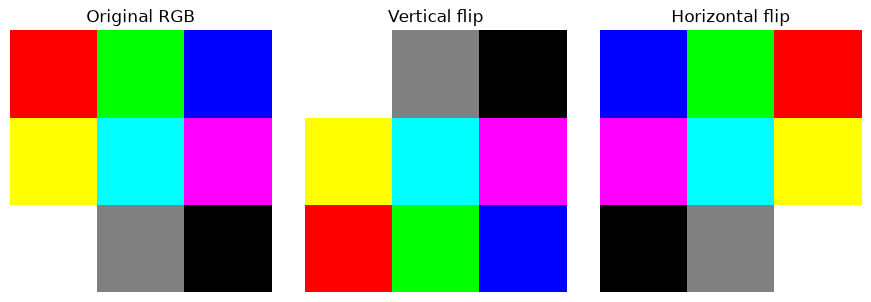

In [18]:
try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

---
## 4. Transposing Arrays

### Array Transposition

In [19]:
# Array Transposition
data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)


### Transposing by Axis


In [20]:
# Transposing by Axis
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))

=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


---
## 5. Stacking and Splitting Arrays

### Splitting Arrays (`np.split`)

In [21]:
# Splitting Arrays (np.split)
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]


### Stacking Arrays (`np.stack`)

In [22]:
# Stacking Arrays (np.stack)
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


### Reshaping Split Arrays


In [23]:
#  Reshaping Split Arrays
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


---
## 6. Independent Student Exercises

### Exercise 1 — Broadcasting in NumPy

Gunakan matriks berikut:

```python
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])
```

1. Tambahkan bonus `[5, 3, 2]` pada **setiap kolom** menggunakan broadcasting.
2. Tambahkan bonus `[1, 4, 2]` pada **setiap baris** dengan `reshape(-1, 1)`.
3. Hitung rata-rata masing-masing kolom dengan `keepdims=True`, lalu kurangkan dari `scores`.
4. Tampilkan `.shape` untuk setiap array bonus dan hasil perhitungan.


In [26]:
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

# bonus per kolom [5, 3, 2]
bonus_kolom = np.array([5, 3, 2])
scores_bonus_kolom = scores + bonus_kolom
print("Bonus per kolom:")
print(scores_bonus_kolom)

# bonus per baris [1, 4, 2] dengan reshape(-1, 1)
bonus_baris = np.array([1, 4, 2]).reshape(-1, 1)
scores_bonus_baris = scores + bonus_baris
print("Bonus per baris:")
print(scores_bonus_baris)

# rata-rata kolom dengan keepdims=True, lalu kurangkan dari scores
kolom_mean = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - kolom_mean
print("Rata-rata kolom:", kolom_mean)
print("Mean kolom - scores:")
print(centered_scores)

# shape setiap array bonus dan hasil perhitungan
print("Shape bonus_kolom:", bonus_kolom.shape)
print("Shape bonus_baris:", bonus_baris.shape)
print("Shape kolom_mean:", kolom_mean.shape)
print("Shape scores + bonus_kolom:", scores_bonus_kolom.shape)
print("Shape scores + bonus_baris:", scores_bonus_baris.shape)
print("Shape mean kolom - scores:", centered_scores.shape)

Bonus per kolom:
[[75 83 92]
 [80 88 97]
 [65 73 82]]
Bonus per baris:
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Rata-rata kolom: [[68.33333333 78.33333333 88.33333333]]
Mean kolom - scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Shape bonus_kolom: (3,)
Shape bonus_baris: (3, 1)
Shape kolom_mean: (1, 3)
Shape scores + bonus_kolom: (3, 3)
Shape scores + bonus_baris: (3, 3)
Shape mean kolom - scores: (3, 3)


### Exercise 2 — Saving and Loading Arrays

Gunakan `temperatures = np.array([[29, 31, 30], [28, 32, 33], [27, 30, 31]])`.

1. Simpan array ke file `week11_temperatures.npy` menggunakan `np.save()`.
2. Buka kembali dengan `np.load()` dan simpan pada variabel baru.
3. Periksa `.shape`, `.ndim`, dan `.dtype` dari hasil pemuatan.
4. Gunakan `np.array_equal()` untuk memeriksa kesamaan array asli dan hasil pemuatan.


In [28]:
temperatures = np.array([[29, 31, 30], [28, 32, 33], [27, 30, 31]])

# simpan ke file .npy
np.save("week11_temperatures.npy", temperatures)
print("Menyimpan file: week11_temperatures.npy")

# buka kembali dan simpan pada variabel baru
loaded_temperatures = np.load("week11_temperatures.npy", allow_pickle=False)
print("Hasil pemuatan (np.load):")
print(loaded_temperatures)

# periksa shape, ndim, dan dtype hasil pemuatan
print("Shape:", loaded_temperatures.shape)
print("Dimensi:", loaded_temperatures.ndim)
print("Tipe Data:", loaded_temperatures.dtype)

# periksa kesamaan array asli dan hasil pemuatan
print("Array asli dan hasil pemuatan sama:", np.array_equal(temperatures, loaded_temperatures))

Menyimpan file: week11_temperatures.npy
Hasil pemuatan (np.load):
[[29 31 30]
 [28 32 33]
 [27 30 31]]
Shape: (3, 3)
Dimensi: 2
Tipe Data: int64
Array asli dan hasil pemuatan sama: True


### Exercise 3 — Image Arrays and Transformations

Gunakan gambar RGB berikut:

```python
image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)
```

1. Tampilkan bentuk gambar dan matriks kanal Red, Green, dan Blue.
2. Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0.
3. Tambahkan kecerahan 30 pada semua kanal dengan `astype()`, `np.clip()`, dan `astype(np.uint8)`.
4. Balik gambar secara horizontal serta vertikal menggunakan `np.flip()`, lalu periksa piksel pada posisi `[0, 0]` di setiap hasil.


In [30]:
image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)

# menampilkan bentuk gambar dan matriks kanal Red, Green, Blue
red_channel = image[:, :, 0]
green_channel = image[:, :, 1]
blue_channel = image[:, :, 2]

print("Bentuk gambar:", image.shape)
print("Matriks kanal Red:")
print(red_channel)
print("Matriks kanal Green:")
print(green_channel)
print("Matriks kanal Blue:")
print(blue_channel)

# buat salinan gambar, ubah seluruh kanal Blue menjadi 0
blue_image = image.copy()
blue_image[:, :, 2] = 0

print("Gambar asli (tidak berubah):")
print(image)
print("Salinan gambar dengan kanal Blue = 0:")
print(blue_image)

# tambah kecerahan 30 pada semua kanal
brightened_image = np.clip(image.astype(np.int16) + 30, 0, 255).astype(np.uint8)

print("Gambar setelah kecerahan +30:")
print(brightened_image)

# balik gambar secara horizontal dan vertikal dengan dan periksa piksel pada posisi [0, 0]
horizontal_flip = np.flip(image, axis=1)
vertical_flip = np.flip(image, axis=0)

print("Piksel [0, 0] gambar asli:", image[0, 0])
print("Piksel [0, 0] flip horizontal (axis=1):", horizontal_flip[0, 0])
print("Piksel [0, 0] flip vertikal (axis=0):", vertical_flip[0, 0])

Bentuk gambar: (2, 2, 3)
Matriks kanal Red:
[[255   0]
 [  0 255]]
Matriks kanal Green:
[[  0 255]
 [  0 255]]
Matriks kanal Blue:
[[  0   0]
 [255 255]]
Gambar asli (tidak berubah):
[[[255   0   0]
  [  0 255   0]]

 [[  0   0 255]
  [255 255 255]]]
Salinan gambar dengan kanal Blue = 0:
[[[255   0   0]
  [  0 255   0]]

 [[  0   0   0]
  [255 255   0]]]
Gambar setelah kecerahan +30:
[[[255  30  30]
  [ 30 255  30]]

 [[ 30  30 255]
  [255 255 255]]]
Piksel [0, 0] gambar asli: [255   0   0]
Piksel [0, 0] flip horizontal (axis=1): [  0 255   0]
Piksel [0, 0] flip vertikal (axis=0): [  0   0 255]


### Exercise 4 — Transposing Arrays

Gunakan `arr = np.arange(24).reshape(2, 3, 4)`.

1. Periksa `.shape` array awal.
2. Gunakan `np.transpose()` untuk mengubah urutan sumbu menjadi `(1, 0, 2)`.
3. Gunakan `np.swapaxes()` untuk menghasilkan bentuk array yang sama.
4. Buat gambar `image = np.zeros((4, 5, 3))`, ubah dari HWC menjadi CHW, lalu kembalikan ke HWC.

In [37]:
arr = np.arange(24).reshape(2, 3, 4)

# periksa shape array awal
print("Shape array awal:", arr.shape)

# mengubah urutan sumbu jadi (1, 0, 2)
transposed = np.transpose(arr, axes=(1, 0, 2))
print("Shape hasil np.transpose:", transposed.shape)
print(transposed)

# gunakan np.swapaxes() untuk menghasilkan bentuk yang sama
swapped = np.swapaxes(arr, 0, 1)
print("Shape hasil np.swapaxes:", swapped.shape)
print("Hasil transpose dan swapaxes sama:", np.array_equal(transposed, swapped))

# buat gambar, ubah dari HWC menjadi CHW dan kembalikan ke HWC
image = np.zeros((4, 5, 3))
print("Shape HWC (awal):", image.shape)

image_chw = np.transpose(image, axes=(2, 0, 1))
print("Shape CHW:", image_chw.shape)

image_hwc = np.transpose(image_chw, axes=(1, 2, 0))
print("Shape HWC (kembali):", image_hwc.shape)
print("Sama dengan gambar awal:", np.array_equal(image, image_hwc))

Shape array awal: (2, 3, 4)
Shape hasil np.transpose: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]
Shape hasil np.swapaxes: (3, 2, 4)
Hasil transpose dan swapaxes sama: True
Shape HWC (awal): (4, 5, 3)
Shape CHW: (3, 4, 5)
Shape HWC (kembali): (4, 5, 3)
Sama dengan gambar awal: True


### Exercise 5 — Stacking and Splitting Arrays

Gunakan `data = np.arange(1, 13).reshape(3, 4)`.

1. Bagi `data` menjadi dua bagian menurut kolom menggunakan `np.split()`.
2. Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan `reshape(-1)`.
3. Gabungkan kedua vektor memakai `np.stack(axis=0)` dan periksa bentuknya.
4. Gunakan `np.array_split()` untuk membagi `np.arange(10)` menjadi tiga bagian; bandingkan ukuran setiap bagian.

In [40]:
data = np.arange(1, 13).reshape(3, 4)

print("Data awal:")
print(data)

# bagi data menjadi dua bagian menurut kolom
left_part, right_part = np.split(data, 2, axis=1)
print("Bagian kiri:")
print(left_part)
print("Bagian kanan:")
print(right_part)

# periksa bentuk bagian, lalu ubah menjadi vektor 1D
print("Shape bagian kiri:", left_part.shape)
print("Shape bagian kanan:", right_part.shape)

left_vector = left_part.reshape(-1)
right_vector = right_part.reshape(-1)
print("Vektor kiri:", left_vector, "shape:", left_vector.shape)
print("Vektor kanan:", right_vector, "shape:", right_vector.shape)

# gabungkan kedua vektor dan periksa bentuknya
stacked = np.stack((left_vector, right_vector), axis=0)
print("Hasil gabungan (axis=0):")
print(stacked)
print("Shape hasil gabungan:", stacked.shape)

# bagi menjadi tiga bagian; bandingkan ukuran tiap bagian
parts = np.array_split(np.arange(10), 3)
for i, part in enumerate(parts):
    print(f"Bagian {i + 1}:", part, "ukuran:", part.size)

Data awal:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Bagian kiri:
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Bagian kanan:
[[ 3  4]
 [ 7  8]
 [11 12]]
Shape bagian kiri: (3, 2)
Shape bagian kanan: (3, 2)
Vektor kiri: [ 1  2  5  6  9 10] shape: (6,)
Vektor kanan: [ 3  4  7  8 11 12] shape: (6,)
Hasil gabungan (axis=0):
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
Shape hasil gabungan: (2, 6)
Bagian 1: [0 1 2 3] ukuran: 4
Bagian 2: [4 5 6] ukuran: 3
Bagian 3: [7 8 9] ukuran: 3


### Exercise 6 — Integrated Statistical Practice

Gunakan data intensitas curah hujan (baris = hari, kolom = lokasi):

```python
rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])
```

1. Hitung rata-rata tiap lokasi, lalu lakukan **centering** menggunakan broadcasting.
2. Simpan hasil centering ke file `week11_centered_rainfall.npy`, kemudian muat kembali.
3. Ubah susunan data hasil pemuatan dari `(hari, lokasi)` menjadi `(lokasi, hari)` dengan `.T`.
4. Bagi data hasil transposisi menjadi dua bagian menurut kolom menggunakan `np.split()`.
5. Gabungkan kembali kedua bagian dengan `np.concatenate(axis=1)` dan buktikan hasilnya sama dengan data sebelum dibagi.

In [44]:
rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])

# mean tiap lokasi, lalu centering
location_means = np.mean(rainfall, axis=0, keepdims=True)
centered_rainfall = rainfall - location_means
print("Rata-rata tiap lokasi:", location_means)
print("Shape rata-rata:", location_means.shape)
print("Hasil centering:")
print(centered_rainfall)
print("Rata-rata setelah centering:", np.mean(centered_rainfall, axis=0))

# simpan hasil centering, lalu muat kembali
np.save("week11_centered_rainfall.npy", centered_rainfall)
print("Menyimpan file: week11_centered_rainfall.npy")

loaded_centered = np.load("week11_centered_rainfall.npy", allow_pickle=False)
print("Hasil pemuatan:")
print(loaded_centered)
print("Shape hasil pemuatan:", loaded_centered.shape)

# ubah susunan data hasil pemuatan
transposed = loaded_centered.T
print("Shape setelah transposisi:", transposed.shape)
print(transposed)

# bagi data hasil transposisi menjadi dua bagian menurut kolom
left_part, right_part = np.split(transposed, 2, axis=1)
print("Bagian kiri, shape:", left_part.shape)
print(left_part)
print("Bagian kanan, shape:", right_part.shape)
print(right_part)

# gabungkan kembali kedua bagian dan buktikan hasilnya sama seperti awal
rejoined = np.concatenate((left_part, right_part), axis=1)
print("Hasil penggabungan, shape:", rejoined.shape)
print("Sama dengan data sebelum dibagi:", np.array_equal(transposed, rejoined))

Rata-rata tiap lokasi: [[12.5  10.    6.25]]
Shape rata-rata: (1, 3)
Hasil centering:
[[-0.5  -2.   -1.25]
 [-2.5   5.    0.75]
 [ 7.5   1.    2.75]
 [-4.5  -4.   -2.25]]
Rata-rata setelah centering: [0. 0. 0.]
Menyimpan file: week11_centered_rainfall.npy
Hasil pemuatan:
[[-0.5  -2.   -1.25]
 [-2.5   5.    0.75]
 [ 7.5   1.    2.75]
 [-4.5  -4.   -2.25]]
Shape hasil pemuatan: (4, 3)
Shape setelah transposisi: (3, 4)
[[-0.5  -2.5   7.5  -4.5 ]
 [-2.    5.    1.   -4.  ]
 [-1.25  0.75  2.75 -2.25]]
Bagian kiri, shape: (3, 2)
[[-0.5  -2.5 ]
 [-2.    5.  ]
 [-1.25  0.75]]
Bagian kanan, shape: (3, 2)
[[ 7.5  -4.5 ]
 [ 1.   -4.  ]
 [ 2.75 -2.25]]
Hasil penggabungan, shape: (3, 4)
Sama dengan data sebelum dibagi: True
